In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import joblib
import os

In [2]:
#Load the cleaned dataset
df = pd.read_csv("../data/processed/cleaned_data.csv")
print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

C:\Users\Sumana Biswas\AppData\Local\Temp\ipykernel_1864\717058425.py:2: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/cleaned_data.csv")


Dataset loaded successfully!
Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,0
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,0
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,0
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,0
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,0


In [3]:
#Prepare the features and target
# Remove identifiers and columns with excessive missingness
drop_columns = [
    "encounter_id",
    "patient_nbr",
    "weight"
]

df.drop(columns=drop_columns, inplace=True, errors="ignore")

# Separate features and target
X = df.drop("readmitted", axis=1)
y = df["readmitted"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (101766, 46)
Target shape: (101766,)

Target distribution:
readmitted
0    90409
1    11357
Name: count, dtype: int64


In [4]:
# Identify hospital codes that represent categories
categorical_ids = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

for col in categorical_ids:
    if col in X.columns:
        X[col] = X[col].astype(str)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 81412
Testing records: 20354


In [5]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 8
Categorical features: 38


C:\Users\Sumana Biswas\AppData\Local\Temp\ipykernel_1864\2101899371.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [6]:
#Now create the preprocessing pipeline
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [7]:
#Train Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [8]:
#Train Random Forest
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [11]:
#Evaluate both models
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, zero_division=0))
    print("Recall:", recall_score(y_test, predictions, zero_division=0))
    print("F1 Score:", f1_score(y_test, predictions, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_test, probabilities))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    return predictions

#Evaluate Logistic Regression  
print("LOGISTIC REGRESSION RESULTS")

lr_predictions = evaluate_model(
    logistic_model,
    X_test,
    y_test
)  

#Evaluate Random Forest
print("RANDOM FOREST RESULTS")

rf_predictions = evaluate_model(
    random_forest_model,
    X_test,
    y_test
)

LOGISTIC REGRESSION RESULTS
Accuracy: 0.6576102977301759
Precision: 0.18049510337323177
Recall: 0.5843240863055923
F1 Score: 0.2757975683258859
ROC-AUC: 0.677336070552701

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.67      0.78     18083
           1       0.18      0.58      0.28      2271

    accuracy                           0.66     20354
   macro avg       0.55      0.63      0.53     20354
weighted avg       0.84      0.66      0.72     20354

RANDOM FOREST RESULTS
Accuracy: 0.8887687923749632
Precision: 0.6521739130434783
Recall: 0.0066050198150594455
F1 Score: 0.013077593722755012
ROC-AUC: 0.6745457543696267

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18083
           1       0.65      0.01      0.01      2271

    accuracy                           0.89     20354
   macro avg       0.77      0.50      0.48     20354
weighted avg

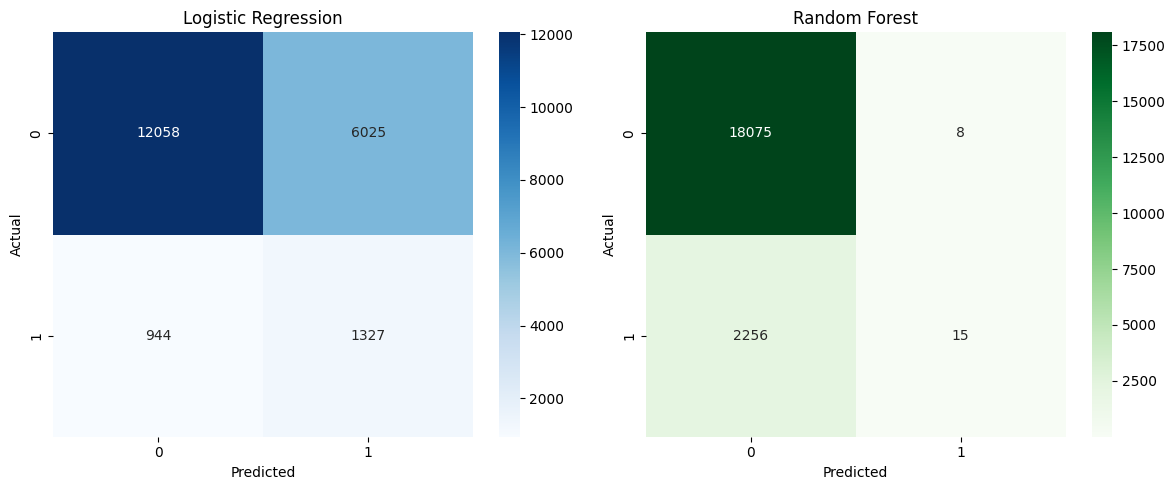

In [12]:
#Visualize model performance
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
sns.heatmap(
    confusion_matrix(y_test, lr_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest
sns.heatmap(
    confusion_matrix(y_test, rf_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

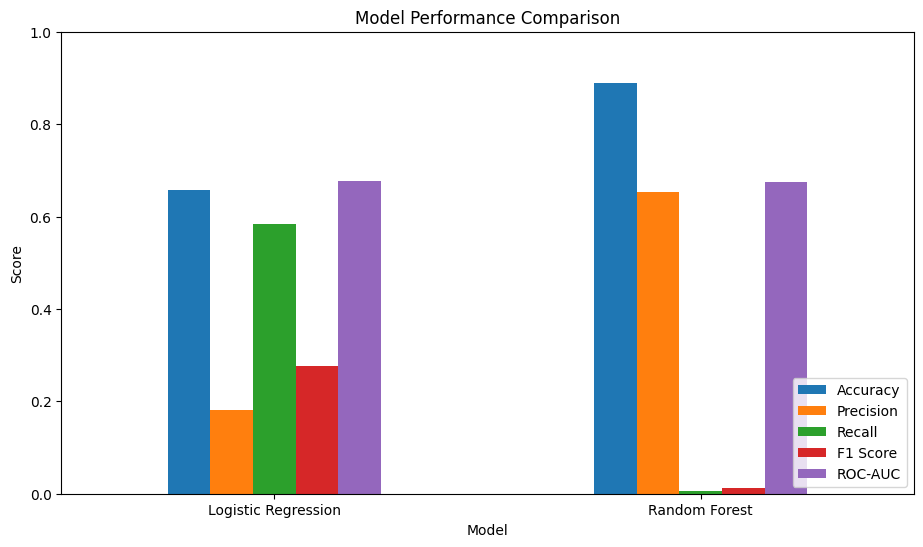

In [14]:
#Compare both models
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, random_forest_model.predict_proba(X_test)[:, 1])
    ]
})

results
results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [15]:
#Save the trained model
lr_f1 = f1_score(y_test, lr_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

if lr_f1 >= rf_f1:
    best_model = logistic_model
    best_model_name = "Logistic Regression"
else:
    best_model = random_forest_model
    best_model_name = "Random Forest"

print("Selected model:", best_model_name)

#Now save it
os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/hospital_readmission_model.pkl"
)

print("Model saved successfully!")

Selected model: Logistic Regression
Model saved successfully!
